# Aprendizado de Máquina versus Escore de Mayo: qual vale mais a pena na predição de óbito em cirrose biliar primária?

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/claytonchagas/ml4health/blob/main/ml4health_cbp_mayo.ipynb)

**TCC00367, Introdução ao Aprendizado de Máquina para Saúde (PGC/UFF).** Clayton Escouper das Chagas.

Notebook de demonstração do projeto. Pergunta: quanto o aprendizado de máquina acrescenta a um modelo de regressão com as 5 variáveis de rotina do Escore de Risco de Mayo (1989) na predição de óbito em até 5 anos, e a que custo? O desenho é 2 x 2: **regressão** e **aprendizado de máquina**, cada um com as **5 variáveis de Mayo** e com as **17 variáveis** do dataset, nos mesmos folds. A leitura vertical compara os pipelines de cada família com as mesmas variáveis (e uma análise de sensibilidade dá às árvores o mesmo pré-processamento da regressão, aproximando a comparação do efeito do algoritmo); a horizontal, o efeito das variáveis extras.

Tempo de execução: cerca de 35 a 40 minutos em CPU com 2 núcleos (o Colab gratuito serve). Para uma execução rápida de teste, mude `N_REP` para 1 na seção de hiperparâmetros.

## 1. Dependências do ambiente de execução

In [1]:
# Instala apenas o que faltar (funciona no Colab e em ambiente local)
import importlib.util, subprocess, sys
faltando = [p for p in ["ucimlrepo", "xgboost", "sklearn", "pandas", "numpy", "matplotlib"] if importlib.util.find_spec(p) is None]
if faltando:
    nomes_pip = {"sklearn": "scikit-learn"}
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *[nomes_pip.get(p, p) for p in faltando]])

import os
os.makedirs("resultados", exist_ok=True); os.makedirs("figs", exist_ok=True)

import sys, sklearn, xgboost, pandas, numpy, matplotlib
print("Python", sys.version.split()[0])
for m in (sklearn, xgboost, pandas, numpy, matplotlib):
    print(f"{m.__name__:12s} {m.__version__}")

Python 3.13.18
sklearn      1.9.1
xgboost      3.4.1
pandas       3.0.5
numpy        2.5.3
matplotlib   3.11.2


## 2. Etapas de execução

### 2.1 Bibliotecas utilizadas

In [2]:
import hashlib
import os
import urllib.request
import warnings
# Silencia so avisos de API (FutureWarning/DeprecationWarning). Avisos de convergencia NAO sao silenciados:
# sao contados por modelo e por fold e reportados (auditoria, A-02).
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

SEMENTE = 2026
HORIZONTE = 1826  # 5 anos em dias
UCI_ID = 878
URL_ESPELHO = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/survival/pbc.csv"
# Copia versionada no repositorio (mesmo conteudo do espelho Rdatasets), usada na execucao oficial
CAMINHO_LOCAL = "data/pbc_rdatasets.csv"
URL_REPO = "https://raw.githubusercontent.com/claytonchagas/ml4health/main/data/pbc_rdatasets.csv"
SHA256_LOCAL = "797ea9b6abfec34297ef07f361a2e0bfdd90c3c2def180adf8547ea30e75b613"

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

### 2.2 Funções de apoio

As funções estão agrupadas por papel: carga e codificação dos dados, Escore de Mayo, pipelines dos modelos, métricas e validação, experimento de vazamento e validação quase externa. Todo pré-processamento que aprende com os dados (imputação, padronização, ajuste de hiperparâmetros) fica **dentro** de um `Pipeline`, e portanto é refeito em cada partição de treino; o conjunto de teste nunca influencia nenhuma decisão.

#### Carga e codificação dos dados

In [3]:
def carregar_dados(fonte="local", caminho=CAMINHO_LOCAL):
    """Carrega a coorte de 418 pacientes com os nomes de colunas do UCI 878.
    fonte="local" (padrao, reprodutivel): usa a copia versionada em data/ (baixa do repositorio se nao existir,
        por exemplo no Colab) e verifica o checksum SHA-256; aborta se o arquivo diferir.
    fonte="uci": baixa o dataset oficial pelo ucimlrepo (id 878); falha explicitamente se o servidor nao responder.
    Devolve (DataFrame, descricao da origem)."""
    if fonte == "uci":
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=UCI_ID)
        # N_Days tem papel "Other" no UCI e so aparece na tabela original, nao em features/targets
        df = ds.data.original.copy().replace({"NA": np.nan})
        for c in ["N_Days", "Age", "Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos", "SGOT",
                  "Tryglicerides", "Platelets", "Prothrombin", "Stage"]:
            df[c] = pd.to_numeric(df[c], errors="coerce")
        df["Age"] = df["Age"] / 365.25  # dias -> anos
        return df, "UCI 878 (ucimlrepo)"
    if fonte != "local":
        raise ValueError("fonte deve ser 'local' ou 'uci'")
    if not os.path.exists(caminho):
        os.makedirs(os.path.dirname(caminho) or ".", exist_ok=True)
        urllib.request.urlretrieve(URL_REPO, caminho)
    sha = hashlib.sha256(open(caminho, "rb").read()).hexdigest()
    if sha != SHA256_LOCAL:
        raise ValueError(f"Checksum de {caminho} difere do esperado ({sha} != {SHA256_LOCAL})")
    r = pd.read_csv(caminho)
    yn = lambda s: s.map({1.0: "Y", 0.0: "N"})
    df = pd.DataFrame({
        "ID": r["id"], "N_Days": r["time"],
        "Status": r["status"].map({0: "C", 1: "CL", 2: "D"}),
        "Drug": r["trt"].map({1.0: "D-penicillamine", 2.0: "Placebo"}),
        "Age": r["age"], "Sex": r["sex"].str.upper(),
        "Ascites": yn(r["ascites"]), "Hepatomegaly": yn(r["hepato"]), "Spiders": yn(r["spiders"]),
        "Edema": r["edema"].map({0.0: "N", 0.5: "S", 1.0: "Y"}),
        "Bilirubin": r["bili"], "Cholesterol": r["chol"], "Albumin": r["albumin"], "Copper": r["copper"],
        "Alk_Phos": r["alk.phos"], "SGOT": r["ast"], "Tryglicerides": r["trig"],
        "Platelets": r["platelet"], "Prothrombin": r["protime"], "Stage": r["stage"],
    })
    return df, f"copia local de survival::pbc (espelho do UCI 878), SHA-256 {sha[:12]}..."


def codificar(df):
    """Codificacao numerica das variaveis categoricas (sem imputar)."""
    X = pd.DataFrame(index=df.index)
    X["Age"] = df["Age"]
    X["Sex_M"] = (df["Sex"] == "M").astype(float)
    X["Edema"] = df["Edema"].map({"N": 0.0, "S": 0.5, "Y": 1.0})
    for c in ["Ascites", "Hepatomegaly", "Spiders"]:
        X[c] = df[c].map({"Y": 1.0, "N": 0.0})
    X["Drug_Dpen"] = df["Drug"].map({"D-penicillamine": 1.0, "Placebo": 0.0})
    for c in ["Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos", "SGOT",
              "Tryglicerides", "Platelets", "Prothrombin", "Stage"]:
        X[c] = df[c].astype(float)
    return X


def rotulo_5anos(df):
    """1 = obito ate 5 anos; 0 = vivo aos 5 anos; NaN = saiu antes dos 5 anos sem obito (censura/transplante)."""
    y = pd.Series(np.nan, index=df.index)
    y[(df["Status"] == "D") & (df["N_Days"] <= HORIZONTE)] = 1.0
    y[df["N_Days"] > HORIZONTE] = 0.0
    return y


MAYO5 = ["Age", "Bilirubin", "Albumin", "Prothrombin", "Edema"]
TODAS17 = ["Age", "Sex_M", "Drug_Dpen", "Ascites", "Hepatomegaly", "Spiders", "Edema",
           "Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos", "SGOT",
           "Tryglicerides", "Platelets", "Prothrombin", "Stage"]
LOG_LAB = ["Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos", "SGOT", "Tryglicerides", "Prothrombin"]

#### Escore de Risco de Mayo (Dickson et al., 1989)

In [4]:
# Dickson et al. (1989). Modelo FINAL: formula de uso da p. 6, estimada com os 418 pacientes (inclui todos os
# pacientes usados como teste neste estudo; por isso e apresentado apenas como referencia historica).
COEF_MAYO = {"Age": 0.039, "log_Bilirubin": 0.871, "log_Albumin": -2.53, "log_Prothrombin": 2.38, "Edema": 0.859}
# Modelo INICIAL: Tabela 2, p. 4, estimado so com os 312 pacientes randomizados. Nao viu os 106 nao randomizados,
# e por isso e o comparador historico valido na validacao quase externa.
COEF_MAYO_INICIAL = {"Age": 0.0333, "log_Bilirubin": 0.8792, "log_Albumin": -3.053, "log_Prothrombin": 3.016,
                     "Edema": 0.7847}
COEFS = {"final": COEF_MAYO, "inicial": COEF_MAYO_INICIAL}


def escore_mayo(X, coef=COEF_MAYO):
    """Escore de risco de Mayo (Dickson et al., 1989): R = soma dos coeficientes x variaveis (logaritmo natural)."""
    return (coef["Age"] * X["Age"] + coef["log_Bilirubin"] * np.log(X["Bilirubin"])
            + coef["log_Albumin"] * np.log(X["Albumin"])
            + coef["log_Prothrombin"] * np.log(X["Prothrombin"]) + coef["Edema"] * X["Edema"])


class MayoOriginal(BaseEstimator, ClassifierMixin):
    """Usa os coeficientes de 1989 sem reestimar (versao 'final', n=418, ou 'inicial', n=312). A ordenacao
    (AUROC) e a do escore original; para obter probabilidades, recalibra apenas intercepto e inclinacao no treino."""
    def __init__(self, versao="final"):
        self.versao = versao

    def fit(self, X, y):
        X = pd.DataFrame(X, columns=MAYO5)
        med = X.median()
        self.med_ = med
        r = escore_mayo(X.fillna(med), COEFS[self.versao]).to_numpy().reshape(-1, 1)
        self.recal_ = LogisticRegression(C=1e6).fit(r, y)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        X = pd.DataFrame(X, columns=MAYO5).fillna(self.med_)
        r = escore_mayo(X, COEFS[self.versao]).to_numpy().reshape(-1, 1)
        return self.recal_.predict_proba(r)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# Probabilidade original do modelo de Cox final (Dickson et al., 1989, p. 6 e Tabela 4):
# S(t) = S0(t) ** exp(R - 5,07), com S0(5 anos) = 0,774 e 5,07 = media de R nos 418 pacientes.
S0_5ANOS = 0.774
R_MEDIO = 5.07


class MayoProbOriginal(BaseEstimator, ClassifierMixin):
    """Probabilidade de obito em 5 anos do modelo de Cox final publicado, sem nenhum ajuste:
    1 - S0(5) ** exp(R - 5,07). Do treino, aprende apenas a mediana para imputar ausentes.
    E crescente em R, entao sua AUROC e exatamente a do escore original."""
    def fit(self, X, y):
        self.med_ = pd.DataFrame(X, columns=MAYO5).median()
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        X = pd.DataFrame(X, columns=MAYO5).fillna(self.med_)
        r = escore_mayo(X, COEF_MAYO).to_numpy()
        p = 1 - S0_5ANOS ** np.exp(r - R_MEDIO)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

#### Pipelines dos modelos e grades de hiperparâmetros

In [5]:
def _log_cols(cols):
    idx = [i for i, c in enumerate(cols) if c in LOG_LAB]
    def f(A):
        A = np.array(A, dtype=float, copy=True)
        A[:, idx] = np.log(A[:, idx])
        return A
    return FunctionTransformer(f)


def pipe_regressao(cols, penalizada):
    imput = SimpleImputer(strategy="median") if cols == MAYO5 else IterativeImputer(random_state=SEMENTE, max_iter=10)
    passos = [("log", _log_cols(cols)), ("imput", imput), ("esc", StandardScaler())]
    if penalizada:
        clf = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=1.0, max_iter=5000,
                                 random_state=SEMENTE)
    else:
        clf = LogisticRegression(C=1e6, max_iter=5000)
    return Pipeline(passos + [("clf", clf)])


def pipe_rf(cols):
    imput = SimpleImputer(strategy="median") if cols == MAYO5 else IterativeImputer(random_state=SEMENTE, max_iter=10)
    return Pipeline([("imput", imput), ("clf", RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1))])


def pipe_xgb(cols):
    # XGBoost aceita ausentes nativamente; nao imputamos (o modelo aprende a direcao dos ausentes)
    return Pipeline([("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8,
                                           colsample_bytree=0.8, eval_metric="logloss", random_state=SEMENTE,
                                           n_jobs=-1, verbosity=0))])


def pipe_arvore_preproc_rl(algoritmo):
    """Analise de sensibilidade (auditoria, A-04): random forest ou XGBoost com 17 variaveis recebendo EXATAMENTE
    o mesmo pre-processamento da regressao logistica com 17 variaveis (logaritmo dos laboratorios, imputacao
    iterativa nessa escala e padronizacao). Arvores sao invariantes a transformacoes monotonicas, entao a unica
    diferenca restante em relacao a regressao e o algoritmo (e seus hiperparametros)."""
    base = pipe_regressao(TODAS17, True).steps[:-1]  # log, imputacao iterativa, padronizacao
    if algoritmo == "rf":
        clf = RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1)
    else:
        clf = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, colsample_bytree=0.8,
                            eval_metric="logloss", random_state=SEMENTE, n_jobs=-1, verbosity=0)
    return Pipeline(base + [("clf", clf)])


# Grades definidas antes de qualquer resultado, com faixas usuais para dados tabulares pequenos; nao foram
# alteradas depois de ver o desempenho. Orcamento igual para todos: 12 configuracoes sorteadas.
N_CONFIG = 12

GRADES = {
    "rl_pen": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0], "clf__l1_ratio": [0.0, 0.5, 1.0]},
    "rf": {"clf__min_samples_leaf": [3, 5, 10, 20], "clf__max_features": ["sqrt", 0.5, 1.0], "clf__max_depth": [None, 4, 6]},
    "xgb": {"clf__n_estimators": [100, 200, 400], "clf__learning_rate": [0.02, 0.05, 0.1],
            "clf__max_depth": [1, 2, 3], "clf__min_child_weight": [1, 5], "clf__reg_lambda": [1.0, 5.0]},
}


def modelos():
    """Celulas do desenho 2 x 2 (mais o escore original). (nome, colunas, estimador, grade ou None)."""
    return [
        ("Mayo 1989 final, prob. original", MAYO5, MayoProbOriginal(), None),
        ("Mayo 1989 final, recalibrado", MAYO5, MayoOriginal("final"), None),
        ("RL, 5 var. (Mayo reestimado)", MAYO5, pipe_regressao(MAYO5, False), None),
        ("RL penalizada, 17 var.", TODAS17, pipe_regressao(TODAS17, True), "rl_pen"),
        ("Random forest, 5 var.", MAYO5, pipe_rf(MAYO5), "rf"),
        ("Random forest, 17 var.", TODAS17, pipe_rf(TODAS17), "rf"),
        ("XGBoost, 5 var.", MAYO5, pipe_xgb(MAYO5), "xgb"),
        ("XGBoost, 17 var.", TODAS17, pipe_xgb(TODAS17), "xgb"),
        # Sensibilidade (A-04): mesmo pre-processamento da RL com 17 variaveis
        ("Random forest, 17 var., pré-proc. da RL", TODAS17, pipe_arvore_preproc_rl("rf"), "rf"),
        ("XGBoost, 17 var., pré-proc. da RL", TODAS17, pipe_arvore_preproc_rl("xgb"), "xgb"),
    ]


def ajustar(est, grade, X, y, semente):
    """Ajusta o modelo (com busca aninhada, se houver grade) apenas nos dados recebidos.
    Devolve (modelo ajustado, hiperparametros escolhidos, avisos de convergencia), em que avisos e a
    lista de textos "Categoria: mensagem", um por aviso distinto (vazia quando nenhum ocorre)."""
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        if grade is None:
            m, hp = clone(est).fit(X, y), {}
        else:
            busca = RandomizedSearchCV(clone(est), GRADES[grade], n_iter=N_CONFIG, scoring="roc_auc",
                                       cv=StratifiedKFold(3, shuffle=True, random_state=semente),
                                       random_state=semente, n_jobs=1, refit=True)
            busca.fit(X, y)
            m, hp = busca.best_estimator_, busca.best_params_
    conv = [f"{a.category.__name__}: {a.message}" for a in avisos if issubclass(a.category, ConvergenceWarning)]
    return m, hp, conv

#### Métricas, validação cruzada e bootstrap

In [6]:
def calibracao(y, p):
    """Calibracao no geral (intercepto) e inclinacao de calibracao, por recalibracao logistica."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    y = np.asarray(y, dtype=float)
    lp = np.log(p / (1 - p))
    # Inclinacao: coeficiente b em logit P(y=1) = a + b * logit(p), sem penalizacao
    incl = LogisticRegression(penalty=None, max_iter=1000).fit(lp.reshape(-1, 1), y).coef_[0, 0]
    # CITL (calibracao no geral): intercepto a em logit P(y=1) = a + 1 * logit(p), isto e, com logit(p) como offset
    # (Van Calster et al., 2016; 2019). Estimado por Newton-Raphson em uma dimensao.
    a = 0.0
    for _ in range(50):
        mu = 1 / (1 + np.exp(-(a + lp)))
        passo = (y - mu).sum() / (mu * (1 - mu)).sum()
        a += passo
        if abs(passo) < 1e-10:
            break
    return a, incl


def metricas(y, p):
    """AUROC; AP = precisao media (average precision): soma da precisao ponderada pelos incrementos de revocacao,
    estimador usual da area sob a curva precisao-revocacao (nao e a integracao trapezoidal); Brier; CITL;
    inclinacao de calibracao."""
    citl, incl = calibracao(y, p)
    return {"AUROC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "CITL": citl, "Incl. calibr.": incl}


def validacao_cruzada(X, y, n_rep=5, n_folds=5, semente=SEMENTE, log=print):
    """Devolve (metricas por fold, predicoes fora-do-fold medias por paciente, hiperparametros por fold).
    As metricas por fold incluem o numero de avisos de convergencia do ajuste daquele fold e seus textos."""
    cv = RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=n_rep, random_state=semente)
    linhas, oof, hiper = [], {}, []
    for nome, cols, est, grade in modelos():
        P = np.full((n_rep, len(y)), np.nan)
        for k, (tr, te) in enumerate(cv.split(X, y)):
            rep = k // n_folds
            m, hp, conv = ajustar(est, grade, X.iloc[tr][cols], y.iloc[tr], semente + k)
            p = m.predict_proba(X.iloc[te][cols])[:, 1]
            P[rep, te] = p
            linhas.append({"Modelo": nome, "Fold": k, **metricas(y.iloc[te].to_numpy(), p), "Avisos de convergência": len(conv),
                           "Mensagens dos avisos": " | ".join(sorted(set(conv)))})
            hiper.append({"Modelo": nome, "Fold": k, **{c.replace("clf__", ""): v for c, v in hp.items()}})
        oof[nome] = P.mean(axis=0)
        log(f"  {nome}: AUROC medio por fold = {np.mean([l['AUROC'] for l in linhas if l['Modelo'] == nome]):.3f}")
    return pd.DataFrame(linhas), pd.DataFrame(oof, index=y.index), pd.DataFrame(hiper)


def bootstrap_diferenca(y, p_ref, p_mod, n=2000, semente=SEMENTE, niveis=(0.95,)):
    """Diferenca de AUROC (modelo menos referencia) e ICs percentis por bootstrap PAREADO de pacientes.
    Os intervalos sao CONDICIONAIS as predicoes fora-do-fold ja obtidas: nao incorporam a variacao de refazer
    o treino, a busca de hiperparametros e as divisoes (exploratorios; ver A-03 da auditoria)."""
    rng = np.random.default_rng(semente)
    y = np.asarray(y); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        d.append(roc_auc_score(y[i], p_mod[i]) - roc_auc_score(y[i], p_ref[i]))
    d = np.array(d)
    ics = [(np.percentile(d, 100 * (1 - nv) / 2), np.percentile(d, 100 * (1 + nv) / 2)) for nv in niveis]
    return roc_auc_score(y, p_mod) - roc_auc_score(y, p_ref), ics


def valor_incremental(y, oof, folds, ref, comparacoes):
    """Tabela de valor incremental contra uma referencia.
    - DeltaAUROC sobre as predicoes fora-do-fold medias, com IC 95% e IC simultaneo de Bonferroni
      (nivel 1 - 0,05/m, m = numero de comparacoes);
    - leitura: 'maior' ou 'menor' so quando o IC de Bonferroni exclui zero; caso contrario,
      'sem evidencia de diferenca' (nao e equivalencia: nenhuma margem foi pre-especificada);
    - dispersao fold a fold (25 folds): media e desvio da diferenca de AUROC dentro de cada fold, que reflete a
      variacao do treino, e fracao de folds em que o modelo superou a referencia."""
    m = len(comparacoes)
    nivel_b = 1 - 0.05 / m
    y = np.asarray(y); linhas = []
    for nome in comparacoes:
        d, ((l95, h95), (lb, hb)) = bootstrap_diferenca(y, oof[ref].to_numpy(), oof[nome].to_numpy(),
                                                       niveis=(0.95, nivel_b))
        a = folds.loc[folds.Modelo == nome].set_index("Fold")["AUROC"]
        b = folds.loc[folds.Modelo == ref].set_index("Fold")["AUROC"]
        df_ = (a - b).dropna()
        leitura = "maior" if lb > 0 else ("menor" if hb < 0 else "sem evidência de diferença")
        linhas.append({"Referência": ref, "Modelo": nome, "ΔAUROC": d, "IC95_inf": l95, "IC95_sup": h95,
                       "Comparações (m)": m, "Nível Bonferroni": nivel_b, "ICBonf_inf": lb, "ICBonf_sup": hb,
                       "Leitura (Bonferroni)": leitura, "Δ fold a fold (média)": df_.mean(),
                       "Δ fold a fold (desvio)": df_.std(), "Folds com ganho (%)": 100 * (df_ > 0).mean()})
    return pd.DataFrame(linhas)


COMPARACOES_SENSIBILIDADE = ["Random forest, 17 var., pré-proc. da RL", "XGBoost, 17 var., pré-proc. da RL"]

COMPARACOES_PRINCIPAIS = ["RL penalizada, 17 var.", "Random forest, 5 var.", "Random forest, 17 var.",
                          "XGBoost, 5 var.", "XGBoost, 17 var."]

#### Experimento de vazamento (enquadramento da competição Kaggle PS3E26)

In [7]:
def experimento_vazamento(df, X, n_rep=5, n_folds=5, semente=SEMENTE):
    """Classificacao em 3 classes (C, CL, D), como na competicao Kaggle PS3E26, com e sem N_Days na entrada."""
    y3 = df["Status"].map({"C": 0, "CL": 1, "D": 2})
    Xs = X[TODAS17].copy()
    Xc = Xs.copy(); Xc["N_Days"] = df["N_Days"]
    cv = RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=n_rep, random_state=semente)
    res = []
    for rotulo, XX in [("sem N_Days", Xs), ("com N_Days", Xc)]:
        for k, (tr, te) in enumerate(cv.split(XX, y3)):
            m = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                              colsample_bytree=0.8, objective="multi:softprob", eval_metric="mlogloss",
                              random_state=semente, n_jobs=-1, verbosity=0)
            m.fit(XX.iloc[tr], y3.iloc[tr])
            p = m.predict_proba(XX.iloc[te])
            res.append({"Entrada": rotulo, "Fold": k, "Log loss": log_loss(y3.iloc[te], p, labels=[0, 1, 2]),
                        "AUROC macro (OvR)": roc_auc_score(y3.iloc[te], p, multi_class="ovr", average="macro"),
                        "Acuracia": (p.argmax(1) == y3.iloc[te].to_numpy()).mean()})
    return pd.DataFrame(res)

#### Validação quase externa

In [8]:
def validacao_quase_externa(df, X, y):
    """Desenvolve nos pacientes do ensaio randomizado; testa nos nao randomizados (Drug ausente).
    Devolve (metricas, n treino, n teste, obitos no teste, hiperparametros escolhidos por modelo)."""
    rot = y.notna()
    tr = rot & df["Drug"].notna(); te = rot & df["Drug"].isna()
    linhas, hiper = [], []
    # O Mayo inicial (n=312) entra aqui como comparador historico valido: foi estimado so nos randomizados.
    lista = [("Mayo 1989 inicial (n=312), recalibrado", MAYO5, MayoOriginal("inicial"), None)] + modelos()
    for nome, cols, est, grade in lista:
        m, hp, conv = ajustar(est, grade, X.loc[tr, cols], y[tr], SEMENTE)
        p = m.predict_proba(X.loc[te, cols])[:, 1]
        linhas.append({"Modelo": nome, **metricas(y[te].to_numpy(), p), "Avisos de convergência": len(conv),
                       "Mensagens dos avisos": " | ".join(sorted(set(conv)))})
        hiper.append({"Cenário": "quase externa", "Modelo": nome, **{c.replace("clf__", ""): v for c, v in hp.items()}})
    return pd.DataFrame(linhas), int(tr.sum()), int(te.sum()), int(y[te].sum()), pd.DataFrame(hiper)

### 2.3 Carregamento e pré-processamento do dataset

**Fonte dos dados.** Com `FONTE_DADOS = "local"` (padrão), o notebook usa a cópia versionada em `data/pbc_rdatasets.csv` (o `survival::pbc` do R, mesma coorte de 418 pacientes e mesmas variáveis do UCI 878, que foi derivado dele); se o arquivo não existir, como no Colab, ele é baixado do repositório, e o checksum SHA-256 é verificado. Com `FONTE_DADOS = "uci"`, o dataset oficial é baixado pelo `ucimlrepo` (id 878). A execução oficial usa `"local"`. A idade é convertida para anos.

**Rótulo.** Óbito em até 5 anos (1.826 dias):
- `Status = D` e `N_Days ≤ 1826` → 1;
- `N_Days > 1826` (qualquer status) → 0 (vivo aos 5 anos, com certeza);
- `Status ∈ {C, CL}` e `N_Days ≤ 1826` → sem rótulo, excluído (saiu antes dos 5 anos sem óbito observado).

`N_Days` é usado **apenas** para construir o rótulo; nunca é variável de entrada (exceto no braço de controle de vazamento, rodado de propósito).

In [9]:
FONTE_DADOS = "local"   # "local" (reprodutível, padrão) ou "uci" (dataset oficial do UCI 878)
df, ORIGEM = carregar_dados(FONTE_DADOS)
X = codificar(df)
y = rotulo_5anos(df)
rot = y.notna()
print("Origem dos dados:", ORIGEM)
print("Pacientes:", len(df))
print("Status:", df["Status"].value_counts().to_dict())
print("Randomizados no ensaio (Drug presente):", int(df["Drug"].notna().sum()), "| não randomizados:", int(df["Drug"].isna().sum()))
print(f"Rotulados para 5 anos: {int(rot.sum())} | óbitos em 5 anos: {int(y.sum())} ({y[rot].mean():.1%}) | excluídos por censura/transplante antes de 5 anos: {int((~rot).sum())}")

Origem dos dados: copia local de survival::pbc (espelho do UCI 878), SHA-256 797ea9b6abfe...
Pacientes: 418
Status: {'C': 232, 'D': 161, 'CL': 25}
Randomizados no ensaio (Drug presente): 312 | não randomizados: 106
Rotulados para 5 anos: 312 | óbitos em 5 anos: 115 (36.9%) | excluídos por censura/transplante antes de 5 anos: 106


In [10]:
# Ausentes por variável (coorte completa) e custo de dados de cada coluna do desenho 2 x 2
aus = X[TODAS17].isna().sum().sort_values(ascending=False)
print(aus[aus > 0].to_string())
comp5 = int(X.loc[rot, MAYO5].notna().all(1).sum()); comp17 = int(X.loc[rot, TODAS17].notna().all(1).sum())
print(f"\nPacientes rotulados com dados completos, sem imputação: 5 variáveis = {comp5} de {int(rot.sum())}; 17 variáveis = {comp17} de {int(rot.sum())}")

Tryglicerides    136
Cholesterol      134
Copper           108
Alk_Phos         106
Drug_Dpen        106
Spiders          106
SGOT             106
Hepatomegaly     106
Ascites          106
Platelets         11
Stage              6
Prothrombin        2

Pacientes rotulados com dados completos, sem imputação: 5 variáveis = 310 de 312; 17 variáveis = 210 de 312


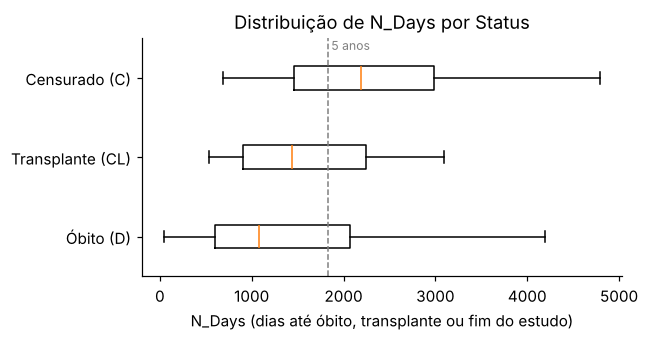

In [11]:
# Por que N_Days não pode ser entrada: ele separa as classes de Status quase sozinho
fig, ax = plt.subplots(figsize=(6, 3.2))
ordem = ["D", "CL", "C"]
ax.boxplot([df.loc[df.Status == s, "N_Days"] for s in ordem], tick_labels=["Óbito (D)", "Transplante (CL)", "Censurado (C)"], vert=False)
ax.axvline(HORIZONTE, ls="--", c="gray", lw=1); ax.text(HORIZONTE + 40, 3.35, "5 anos", color="gray", fontsize=8)
ax.set_xlabel("N_Days (dias até óbito, transplante ou fim do estudo)"); ax.set_title("Distribuição de N_Days por Status")
plt.tight_layout(); plt.savefig("figs/n_days_por_status.png", dpi=200, bbox_inches="tight"); plt.show()

### 2.4 Hiperparâmetros utilizados

- **Validação externa ao ajuste:** validação cruzada estratificada repetida, `N_REP` repetições de 5 folds (padrão 5 x 5 = 25 avaliações); as mesmas 25 divisões para todos os modelos.
- **Ajuste aninhado:** `RandomizedSearchCV` com **12 configurações sorteadas para todos os modelos ajustáveis**, 3 folds internos, critério AUROC, somente no treino de cada fold externo. As grades foram definidas antes de qualquer resultado e não foram alteradas depois.
- **Escore de Mayo final (Dickson et al., 1989, n = 418), referência histórica.** Duas versões, ambas com os coeficientes publicados sem reestimar: (i) **probabilidade original** do modelo de Cox, $1 - 0{,}774^{\exp(R - 5{,}07)}$, sem nenhum ajuste; (ii) **recalibrado no treino**, com intercepto e inclinação de uma regressão logística sobre $R$. Como os coeficientes finais foram estimados com os 418 pacientes desta coorte, nenhuma das duas é uma validação independente (auditoria, A-01 e A-07).
- **Escore de Mayo inicial (n = 312)**, só na validação quase externa: coeficientes da Tabela 2 de Dickson, estimados apenas nos pacientes randomizados, recalibrados no treino.
- **Regressão logística com 5 variáveis (referência principal):** mesma especificação de Mayo (logaritmo de bilirrubina, albumina e protrombina; edema em 0, 0,5 e 1), sem penalização, reestimada em cada fold.
- **Regressão logística com 17 variáveis:** *elastic net* (solver `saga` com semente), laboratórios assimétricos em logaritmo, imputação iterativa, padronização.
- **Random forest:** 300 árvores; grade sobre folha mínima, variáveis por divisão e profundidade. Imputação iterativa na escala original.
- **XGBoost:** ausentes tratados nativamente; grade sobre número de árvores, taxa de aprendizado, profundidade, peso mínimo por folha e regularização L2.
- **Sensibilidade do pré-processamento:** random forest e XGBoost com 17 variáveis recebendo exatamente o pré-processamento da regressão com 17 variáveis (auditoria, A-04).
- **Métricas:** AUROC (principal); **AP** (*average precision*, precisão média: soma da precisão ponderada pelos incrementos de revocação, estimador usual da área sob a curva precisão-revocação, mas não a integração trapezoidal); Brier; CITL (intercepto com o logit da predição como *offset*); inclinação de calibração.
- **Sem balanceamento artificial de classes:** distorceria as probabilidades (Christodoulou et al., 2019).
- **Avisos de convergência** não são silenciados: são contados, têm categoria e mensagem registradas e são reportados após a validação cruzada e na validação quase externa.

In [12]:
N_REP = 5      # repetições da validação cruzada (use 1 para um teste rápido)
N_FOLDS = 5
print("Semente:", SEMENTE, "| horizonte:", HORIZONTE, "dias")
for nome, cols, est, grade in modelos():
    print(f"- {nome:32s} {len(cols):2d} variáveis | grade: {grade if grade else 'sem ajuste'}")
print("\nGrades:")
for k, g in GRADES.items():
    print(" ", k, g)

Semente: 2026 | horizonte: 1826 dias
- Mayo 1989 final, prob. original   5 variáveis | grade: sem ajuste
- Mayo 1989 final, recalibrado      5 variáveis | grade: sem ajuste
- RL, 5 var. (Mayo reestimado)      5 variáveis | grade: sem ajuste
- RL penalizada, 17 var.           17 variáveis | grade: rl_pen
- Random forest, 5 var.             5 variáveis | grade: rf
- Random forest, 17 var.           17 variáveis | grade: rf
- XGBoost, 5 var.                   5 variáveis | grade: xgb
- XGBoost, 17 var.                 17 variáveis | grade: xgb
- Random forest, 17 var., pré-proc. da RL 17 variáveis | grade: rf
- XGBoost, 17 var., pré-proc. da RL 17 variáveis | grade: xgb

Grades:
  rl_pen {'clf__C': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0], 'clf__l1_ratio': [0.0, 0.5, 1.0]}
  rf {'clf__min_samples_leaf': [3, 5, 10, 20], 'clf__max_features': ['sqrt', 0.5, 1.0], 'clf__max_depth': [None, 4, 6]}
  xgb {'clf__n_estimators': [100, 200, 400], 'clf__learning_rate': [0.02, 0.05, 0.1], 'clf__max_depth': [1,

## 3. Execução

### 3.1 Curvas de iteração

Curvas **demonstrativas**, num único corte treino/teste (80/20 estratificado), para mostrar como cada modelo aprende: perda logarítmica do XGBoost por rodada de *boosting*, erro fora-da-bolsa (OOB) do random forest por número de árvores (até 500, para mostrar a estabilização; a avaliação principal usa 300) e AUROC da regressão logística penalizada ao longo da força de regularização. Essas curvas **não participam** da seleção de modelos nem das tabelas de resultados. Na curva do random forest, a imputação é ajustada antes do *bootstrap*, de modo que o erro OOB ali é apenas ilustrativo, não uma validação do pipeline.

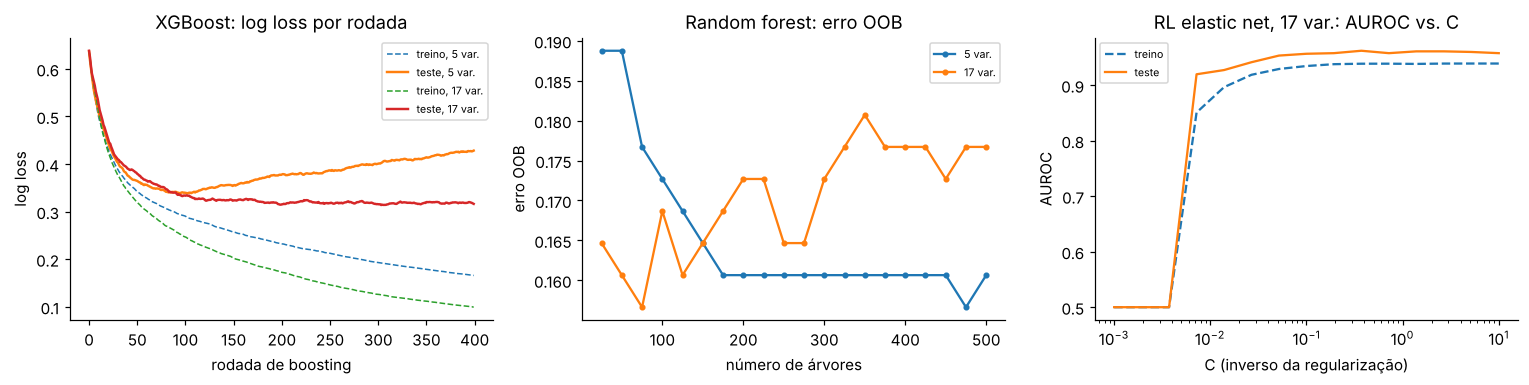

In [13]:
from sklearn.model_selection import train_test_split
Xr, yr = X[rot], y[rot].astype(int)
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=SEMENTE)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))

# (a) XGBoost: log loss por rodada
for cols, nome in [(MAYO5, "5 var."), (TODAS17, "17 var.")]:
    m = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=2, subsample=0.8, colsample_bytree=0.8,
                      eval_metric="logloss", random_state=SEMENTE, verbosity=0)
    m.fit(Xtr[cols], ytr, eval_set=[(Xtr[cols], ytr), (Xte[cols], yte)], verbose=False)
    ev = m.evals_result()
    axs[0].plot(ev["validation_0"]["logloss"], ls="--", lw=1, label=f"treino, {nome}")
    axs[0].plot(ev["validation_1"]["logloss"], lw=1.6, label=f"teste, {nome}")
axs[0].set_title("XGBoost: log loss por rodada"); axs[0].set_xlabel("rodada de boosting"); axs[0].set_ylabel("log loss"); axs[0].legend(fontsize=7)

# (b) Random forest: erro OOB por número de árvores
for cols, nome in [(MAYO5, "5 var."), (TODAS17, "17 var.")]:
    Xi = SimpleImputer(strategy="median").fit(Xtr[cols]).transform(Xtr[cols])
    rf = RandomForestClassifier(warm_start=True, oob_score=True, min_samples_leaf=5, random_state=SEMENTE, n_jobs=-1)
    ns, err = list(range(25, 525, 25)), []
    for n in ns:
        rf.set_params(n_estimators=n); rf.fit(Xi, ytr); err.append(1 - rf.oob_score_)
    axs[1].plot(ns, err, marker="o", ms=3, label=nome)
axs[1].set_title("Random forest: erro OOB"); axs[1].set_xlabel("número de árvores"); axs[1].set_ylabel("erro OOB"); axs[1].legend(fontsize=7)

# (c) Regressão logística penalizada: AUROC de teste ao longo de C
Cs = np.logspace(-3, 1, 15); auc_tr, auc_te = [], []
for c in Cs:
    p = pipe_regressao(TODAS17, True).set_params(clf__C=c, clf__l1_ratio=0.5).fit(Xtr[TODAS17], ytr)
    auc_tr.append(roc_auc_score(ytr, p.predict_proba(Xtr[TODAS17])[:, 1])); auc_te.append(roc_auc_score(yte, p.predict_proba(Xte[TODAS17])[:, 1]))
axs[2].semilogx(Cs, auc_tr, "--", label="treino"); axs[2].semilogx(Cs, auc_te, label="teste")
axs[2].set_title("RL elastic net, 17 var.: AUROC vs. C"); axs[2].set_xlabel("C (inverso da regularização)"); axs[2].set_ylabel("AUROC"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("figs/curvas_iteracao.png", dpi=200, bbox_inches="tight"); plt.show()

### 3.2 Avaliação principal: desenho 2 x 2 em validação cruzada 5 x 5 aninhada

In [14]:
import time
t0 = time.time()
folds, oof, hiper = validacao_cruzada(X[rot], y[rot], n_rep=N_REP, n_folds=N_FOLDS)
folds.to_csv("resultados/folds.csv", index=False); oof.to_csv("resultados/oof.csv")
hiper.to_csv("resultados/hiperparametros.csv", index=False)
print(f"Tempo: {time.time() - t0:.0f} s")
conv = folds.groupby("Modelo", sort=False)["Avisos de convergência"].sum()
print("Avisos de convergência por modelo (soma nos 25 folds, incluindo a busca interna):")
print(conv.to_string() if conv.sum() else "  nenhum")
msgs = sorted({m for s in folds["Mensagens dos avisos"].dropna() for m in str(s).split(" | ") if m})
for m in msgs: print("  ", m)

  Mayo 1989 final, prob. original: AUROC medio por fold = 0.910


  Mayo 1989 final, recalibrado: AUROC medio por fold = 0.910


  RL, 5 var. (Mayo reestimado): AUROC medio por fold = 0.906


  RL penalizada, 17 var.: AUROC medio por fold = 0.915


  Random forest, 5 var.: AUROC medio por fold = 0.893


  Random forest, 17 var.: AUROC medio por fold = 0.903


  XGBoost, 5 var.: AUROC medio por fold = 0.891


  XGBoost, 17 var.: AUROC medio por fold = 0.895


  Random forest, 17 var., pré-proc. da RL: AUROC medio por fold = 0.907


  XGBoost, 17 var., pré-proc. da RL: AUROC medio por fold = 0.899
Tempo: 2131 s
Avisos de convergência por modelo (soma nos 25 folds, incluindo a busca interna):
  nenhum


In [15]:
# Hiperparâmetros escolhidos pela busca aninhada: configuração mais frequente em cada modelo (todas em resultados/hiperparametros.csv)
hp = hiper.dropna(axis=1, how="all")
for nome, g in hp.groupby("Modelo", sort=False):
    g = g.drop(columns=["Modelo", "Fold"]).dropna(axis=1, how="all")
    if g.shape[1]:
        inteiros = {"min_samples_leaf", "max_depth", "n_estimators", "min_child_weight"}  # max_features 1.0 = fração, não 1 variável
        g = g.apply(lambda col: col.map(lambda v: int(v) if col.name in inteiros and isinstance(v, float) and v.is_integer() else v))
        moda = g.astype(str).value_counts().head(1)
        print(f"{nome}: {dict(zip(g.columns, moda.index[0]))} (em {moda.iloc[0]} de {len(g)} folds)")

RL penalizada, 17 var.: {'l1_ratio': '0.0', 'C': '0.01'} (em 7 de 25 folds)
Random forest, 5 var.: {'min_samples_leaf': '3', 'max_features': '1.0', 'max_depth': '4.0'} (em 3 de 25 folds)
Random forest, 17 var.: {'min_samples_leaf': '3', 'max_features': 'sqrt', 'max_depth': '6.0'} (em 3 de 25 folds)
XGBoost, 5 var.: {'max_depth': '2', 'reg_lambda': '5.0', 'n_estimators': '100', 'min_child_weight': '1', 'learning_rate': '0.05'} (em 3 de 25 folds)
XGBoost, 17 var.: {'max_depth': '3', 'reg_lambda': '5.0', 'n_estimators': '100', 'min_child_weight': '1', 'learning_rate': '0.05'} (em 3 de 25 folds)
Random forest, 17 var., pré-proc. da RL: {'min_samples_leaf': '5', 'max_features': 'sqrt', 'max_depth': '4.0'} (em 4 de 25 folds)
XGBoost, 17 var., pré-proc. da RL: {'max_depth': '3', 'reg_lambda': '5.0', 'n_estimators': '100', 'min_child_weight': '1', 'learning_rate': '0.05'} (em 4 de 25 folds)


In [16]:
resumo = folds.drop(columns=["Fold", "Avisos de convergência", "Mensagens dos avisos"]).groupby("Modelo", sort=False).agg(["mean", "std"])
fmt = resumo.copy()
tab = pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(resumo[(c, 'mean')], resumo[(c, 'std')])] for c in ["AUROC", "AP", "Brier", "CITL", "Incl. calibr."]}, index=resumo.index)
tab

,AUROC,AP,Brier,CITL,Incl. calibr.
Modelo,,,,,
"Mayo 1989 final, prob. original",0.910 ± 0.040,0.879 ± 0.054,0.121 ± 0.023,0.334 ± 0.182,1.555 ± 0.441
"Mayo 1989 final, recalibrado",0.910 ± 0.040,0.879 ± 0.054,0.112 ± 0.028,-0.002 ± 0.312,1.097 ± 0.332
"RL, 5 var. (Mayo reestimado)",0.906 ± 0.044,0.871 ± 0.061,0.115 ± 0.032,-0.014 ± 0.325,1.035 ± 0.361
"RL penalizada, 17 var.",0.915 ± 0.035,0.880 ± 0.051,0.121 ± 0.024,0.000 ± 0.252,1.743 ± 0.908
"Random forest, 5 var.",0.893 ± 0.047,0.852 ± 0.066,0.130 ± 0.030,0.013 ± 0.266,1.265 ± 0.603
"Random forest, 17 var.",0.903 ± 0.044,0.862 ± 0.069,0.124 ± 0.026,0.017 ± 0.211,1.568 ± 0.581
"XGBoost, 5 var.",0.891 ± 0.051,0.852 ± 0.072,0.126 ± 0.033,0.041 ± 0.258,1.094 ± 0.340
"XGBoost, 17 var.",0.895 ± 0.042,0.854 ± 0.064,0.126 ± 0.028,0.040 ± 0.265,1.152 ± 0.408
"Random forest, 17 var., pré-proc. da RL",0.907 ± 0.042,0.868 ± 0.063,0.122 ± 0.024,0.003 ± 0.196,1.516 ± 0.599


**Valor incremental.** A referência principal é a regressão logística com as 5 variáveis de Mayo, **reestimada em cada fold** (mesma especificação de Dickson, sem ter visto o fold de teste). O Escore de Mayo publicado não serve de referência para essa inferência porque seus coeficientes finais foram estimados com os 418 pacientes desta coorte (auditoria, achado A-01).

Os intervalos são por bootstrap **pareado** de pacientes sobre as predições fora-do-fold médias. São **condicionais** a essas predições: não incorporam a variação de refazer o treino e a busca de hiperparâmetros, por isso são exploratórios. Para as cinco comparações principais, além do IC 95%, mostramos o IC simultâneo de Bonferroni (99%); só falamos em "maior" ou "menor" quando ele exclui zero. "Sem evidência de diferença" não significa equivalência: nenhuma margem foi definida a priori. A dispersão fold a fold complementa com a variação do treino.

In [17]:
yy = y[rot].to_numpy()
incremental = valor_incremental(yy, oof, folds, "RL, 5 var. (Mayo reestimado)", COMPARACOES_PRINCIPAIS)
incremental.to_csv("resultados/valor_incremental.csv", index=False)
# Referência histórica (exploratória): mesmos modelos contra a probabilidade original do Mayo publicado
historico = valor_incremental(yy, oof, folds, "Mayo 1989 final, prob. original", ["RL, 5 var. (Mayo reestimado)"] + COMPARACOES_PRINCIPAIS)
historico.to_csv("resultados/valor_incremental_vs_mayo_publicado.csv", index=False)
resumo.to_csv("resultados/resumo_cv.csv")
fmt_ic = lambda a, b: f"[{a:+.3f}; {b:+.3f}]"
mostra = lambda t: pd.DataFrame({"Modelo": t.Modelo, "ΔAUROC": t["ΔAUROC"].round(3),
    "IC 95%": [fmt_ic(a, b) for a, b in zip(t.IC95_inf, t.IC95_sup)],
    "IC Bonferroni": [fmt_ic(a, b) for a, b in zip(t.filter(like="ICBonf").iloc[:, 0], t.filter(like="ICBonf").iloc[:, 1])],
    "Leitura": t["Leitura (Bonferroni)"],
    "Δ por fold (média ± desvio)": [f"{m:+.3f} ± {s:.3f}" for m, s in zip(t["Δ fold a fold (média)"], t["Δ fold a fold (desvio)"])],
    "Folds com ganho": [f"{v:.0f}%" for v in t["Folds com ganho (%)"]]})
print("Referência: RL, 5 var. (Mayo reestimado)")
display(mostra(incremental))
print("Referência histórica (exploratória): Mayo 1989 final, probabilidade original")
display(mostra(historico))

Referência: RL, 5 var. (Mayo reestimado)


,Modelo,ΔAUROC,IC 95%,IC Bonferroni,Leitura,Δ por fold (média ± desvio),Folds com ganho
0,"RL penalizada, 17 var.",0.009,[-0.010; +0.030],[-0.017; +0.035],sem evidência de diferença,+0.009 ± 0.027,60%
1,"Random forest, 5 var.",-0.013,[-0.029; +0.003],[-0.035; +0.009],sem evidência de diferença,-0.013 ± 0.019,24%
2,"Random forest, 17 var.",-0.000,[-0.018; +0.016],[-0.022; +0.024],sem evidência de diferença,-0.003 ± 0.018,40%
3,"XGBoost, 5 var.",-0.013,[-0.027; -0.001],[-0.031; +0.003],sem evidência de diferença,-0.016 ± 0.019,20%
4,"XGBoost, 17 var.",-0.006,[-0.025; +0.012],[-0.030; +0.017],sem evidência de diferença,-0.011 ± 0.019,24%


Referência histórica (exploratória): Mayo 1989 final, probabilidade original


,Modelo,ΔAUROC,IC 95%,IC Bonferroni,Leitura,Δ por fold (média ± desvio),Folds com ganho
0,"RL, 5 var. (Mayo reestimado)",-0.007,[-0.016; +0.000],[-0.018; +0.003],sem evidência de diferença,-0.004 ± 0.009,40%
1,"RL penalizada, 17 var.",0.001,[-0.018; +0.020],[-0.024; +0.028],sem evidência de diferença,+0.005 ± 0.024,56%
2,"Random forest, 5 var.",-0.021,[-0.037; -0.006],[-0.044; -0.000],menor,-0.017 ± 0.016,16%
3,"Random forest, 17 var.",-0.008,[-0.025; +0.010],[-0.030; +0.016],sem evidência de diferença,-0.007 ± 0.017,32%
4,"XGBoost, 5 var.",-0.021,[-0.034; -0.009],[-0.038; -0.005],menor,-0.020 ± 0.020,12%
5,"XGBoost, 17 var.",-0.014,[-0.032; +0.004],[-0.040; +0.009],sem evidência de diferença,-0.015 ± 0.019,20%


**Análise de sensibilidade do pré-processamento (achado A-04 da auditoria).** Na coluna de 17 variáveis, os pipelines principais diferem também no tratamento dos dados: a regressão recebe logaritmos e imputação iterativa; o random forest, imputação iterativa na escala original; o XGBoost trata ausentes nativamente. Por isso a leitura vertical principal compara **pipelines**, não só algoritmos. Aqui, random forest e XGBoost recebem **exatamente** o pré-processamento da regressão com 17 variáveis; como árvores são invariantes a transformações monotônicas, a diferença restante é o algoritmo com seus hiperparâmetros. A comparação aproxima o efeito do algoritmo, mas não testa diretamente o efeito do pré-processamento. A referência é a própria regressão com 17 variáveis (IC de Bonferroni para 2 comparações).

In [18]:
sensibilidade = valor_incremental(yy, oof, folds, "RL penalizada, 17 var.", COMPARACOES_SENSIBILIDADE)
sensibilidade.to_csv("resultados/sensibilidade_preprocessamento.csv", index=False)
display(mostra(sensibilidade))

,Modelo,ΔAUROC,IC 95%,IC Bonferroni,Leitura,Δ por fold (média ± desvio),Folds com ganho
0,"Random forest, 17 var., pré-proc. da RL",-0.006,[-0.022; +0.009],[-0.023; +0.011],sem evidência de diferença,-0.008 ± 0.020,40%
1,"XGBoost, 17 var., pré-proc. da RL",-0.013,[-0.028; +0.002],[-0.030; +0.004],sem evidência de diferença,-0.016 ± 0.019,16%


In [19]:
# Tabela 2 x 2: AUROC médio (desvio) e custo de dados
celula = lambda n: f"{resumo.loc[n, ('AUROC','mean')]:.3f} ± {resumo.loc[n, ('AUROC','std')]:.3f}"
t22 = pd.DataFrame({
    f"5 variáveis (elegíveis sem imputação: {comp5})": [celula("RL, 5 var. (Mayo reestimado)") + "  [Mayo 1989 final, ref. histórica: " + celula("Mayo 1989 final, prob. original") + "]",
                                                        celula("Random forest, 5 var.") + " (RF) / " + celula("XGBoost, 5 var.") + " (XGB)"],
    f"17 variáveis (elegíveis sem imputação: {comp17})": [celula("RL penalizada, 17 var."),
                                                          celula("Random forest, 17 var.") + " (RF) / " + celula("XGBoost, 17 var.") + " (XGB)"]},
    index=["Regressão", "Aprendizado de máquina"])
t22

,5 variáveis (elegíveis sem imputação: 310),17 variáveis (elegíveis sem imputação: 210)
Regressão,"0.906 ± 0.044 [Mayo 1989 final, ref. históric...",0.915 ± 0.035
Aprendizado de máquina,0.893 ± 0.047 (RF) / 0.891 ± 0.051 (XGB),0.903 ± 0.044 (RF) / 0.895 ± 0.042 (XGB)


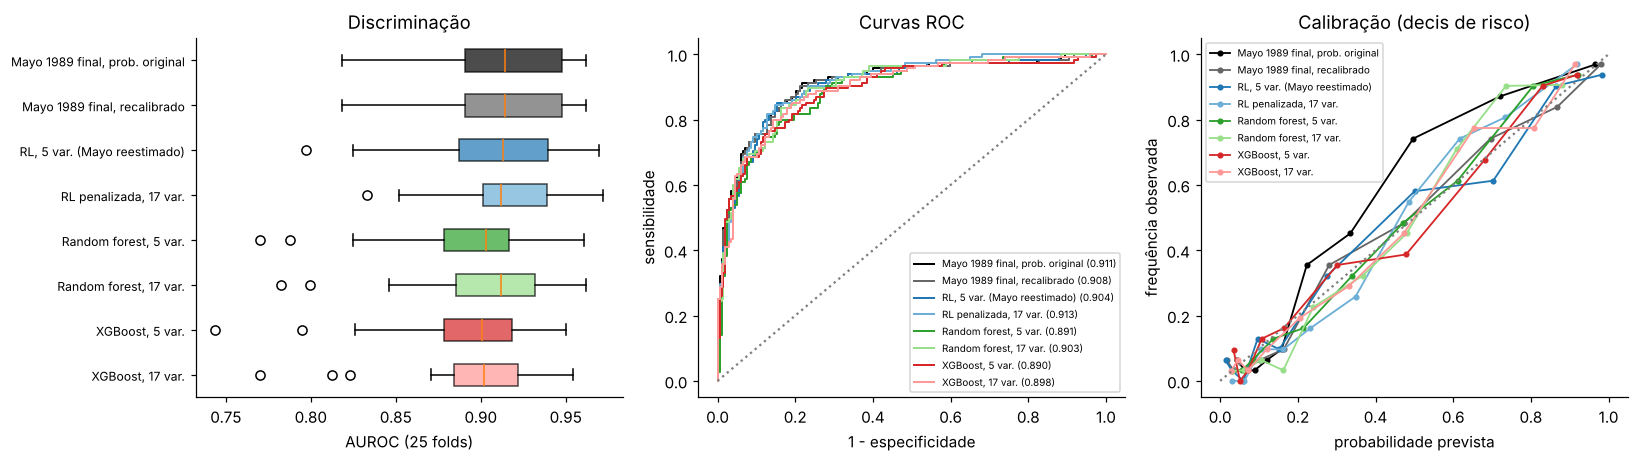

In [20]:
cores = {"Mayo 1989 final, prob. original": "#000000", "Mayo 1989 final, recalibrado": "#666666", "Mayo 1989 inicial (n=312), recalibrado": "#999999", "RL, 5 var. (Mayo reestimado)": "#1f77b4", "RL penalizada, 17 var.": "#6baed6",
         "Random forest, 5 var.": "#2ca02c", "Random forest, 17 var.": "#98df8a", "XGBoost, 5 var.": "#d62728", "XGBoost, 17 var.": "#ff9896",
         "Random forest, 17 var., pré-proc. da RL": "#2ca02c", "XGBoost, 17 var., pré-proc. da RL": "#d62728"}
principais = [c for c in oof.columns if "pré-proc" not in c]  # sensibilidade fica só nas tabelas
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
# (a) AUROC por fold
dados = [folds.loc[folds.Modelo == n, "AUROC"] for n in principais]
bp = axs[0].boxplot(dados, vert=False, patch_artist=True, tick_labels=principais)
for patch, n in zip(bp["boxes"], principais): patch.set_facecolor(cores[n]); patch.set_alpha(.7)
axs[0].set_xlabel("AUROC (25 folds)"); axs[0].set_title("Discriminação"); axs[0].invert_yaxis(); axs[0].tick_params(axis="y", labelsize=8)
# (b) curvas ROC (predições fora-do-fold médias)
for n in principais:
    f, t, _ = roc_curve(yy, oof[n]); axs[1].plot(f, t, c=cores[n], lw=1.3, label=f"{n} ({roc_auc_score(yy, oof[n]):.3f})")
axs[1].plot([0, 1], [0, 1], ":", c="gray"); axs[1].set_xlabel("1 - especificidade"); axs[1].set_ylabel("sensibilidade"); axs[1].set_title("Curvas ROC"); axs[1].legend(fontsize=6.5, loc="lower right")
# (c) curvas de calibração
for n in principais:
    fo, mp = calibration_curve(yy, oof[n], n_bins=10, strategy="quantile"); axs[2].plot(mp, fo, marker="o", ms=3, c=cores[n], lw=1.2, label=n)
axs[2].plot([0, 1], [0, 1], ":", c="gray"); axs[2].set_xlabel("probabilidade prevista"); axs[2].set_ylabel("frequência observada"); axs[2].set_title("Calibração (decis de risco)"); axs[2].legend(fontsize=6.5)
plt.tight_layout(); plt.savefig("figs/discriminacao_roc_calibracao.png", dpi=200, bbox_inches="tight"); plt.show()

### 3.3 Validação quase externa: desenvolvimento nos pacientes do ensaio, teste nos não randomizados

In [21]:
qe, ntr, nte, nev, hqe = validacao_quase_externa(df, X, y)
qe.to_csv("resultados/quase_externa.csv", index=False)
hqe.to_csv("resultados/hiperparametros_quase_externa.csv", index=False)
print(f"Treino: {ntr} pacientes randomizados | Teste: {nte} não randomizados ({nev} óbitos em 5 anos)")
print("No teste, as variáveis exclusivas do ensaio estão ausentes e são imputadas (17 var.) ou tratadas nativamente (XGBoost).")
print("Avisos de convergência:", int(qe["Avisos de convergência"].sum()) or "nenhum")
qe.drop(columns=["Avisos de convergência", "Mensagens dos avisos"]).set_index("Modelo").round(3)

Treino: 244 pacientes randomizados | Teste: 68 não randomizados (30 óbitos em 5 anos)
No teste, as variáveis exclusivas do ensaio estão ausentes e são imputadas (17 var.) ou tratadas nativamente (XGBoost).
Avisos de convergência: nenhum


,AUROC,AP,Brier,CITL,Incl. calibr.
Modelo,,,,,
"Mayo 1989 inicial (n=312), recalibrado",0.865,0.847,0.155,0.325,0.832
"Mayo 1989 final, prob. original",0.873,0.856,0.161,0.577,1.247
"Mayo 1989 final, recalibrado",0.873,0.856,0.149,0.288,0.886
"RL, 5 var. (Mayo reestimado)",0.878,0.844,0.144,0.297,0.882
"RL penalizada, 17 var.",0.874,0.859,0.172,0.460,2.266
"Random forest, 5 var.",0.882,0.876,0.145,0.411,1.152
"Random forest, 17 var.",0.896,0.876,0.145,0.296,1.485
"XGBoost, 5 var.",0.879,0.870,0.145,0.382,0.988
"XGBoost, 17 var.",0.845,0.842,0.179,-0.814,1.004


In [22]:
# Hiperparâmetros escolhidos pela busca no treino da validação quase externa (resultados/hiperparametros_quase_externa.csv)
hqe.drop(columns="Cenário").set_index("Modelo").dropna(axis=0, how="all").dropna(axis=1, how="all")

,l1_ratio,C,min_samples_leaf,max_features,max_depth,reg_lambda,n_estimators,min_child_weight,learning_rate
Modelo,,,,,,,,,
"RL penalizada, 17 var.",0.0,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Random forest, 5 var.",NaN,NaN,3.0,sqrt,6.0,NaN,NaN,NaN,NaN
"Random forest, 17 var.",NaN,NaN,3.0,sqrt,6.0,NaN,NaN,NaN,NaN
"XGBoost, 5 var.",NaN,NaN,NaN,NaN,3.0,5.0,100.0,1.0,0.05
"XGBoost, 17 var.",NaN,NaN,NaN,NaN,3.0,1.0,200.0,1.0,0.05
"Random forest, 17 var., pré-proc. da RL",NaN,NaN,3.0,sqrt,6.0,NaN,NaN,NaN,NaN
"XGBoost, 17 var., pré-proc. da RL",NaN,NaN,NaN,NaN,3.0,1.0,200.0,1.0,0.05


### 3.4 Braço de controle: vazamento por `N_Days` no enquadramento da PS3E26 (3 classes)

In [23]:
vz = experimento_vazamento(df, X, n_rep=N_REP)
vz.to_csv("resultados/vazamento.csv", index=False)
vz_res = vz.drop(columns="Fold").groupby("Entrada").agg(["mean", "std"]).round(3)
vz_res

Log loss        AUROC macro (OvR)        Acuracia       
               mean    std              mean    std     mean    std
Entrada                                                            
com N_Days    0.645  0.086             0.822  0.045    0.763  0.032
sem N_Days    0.753  0.089             0.788  0.043    0.721  0.037

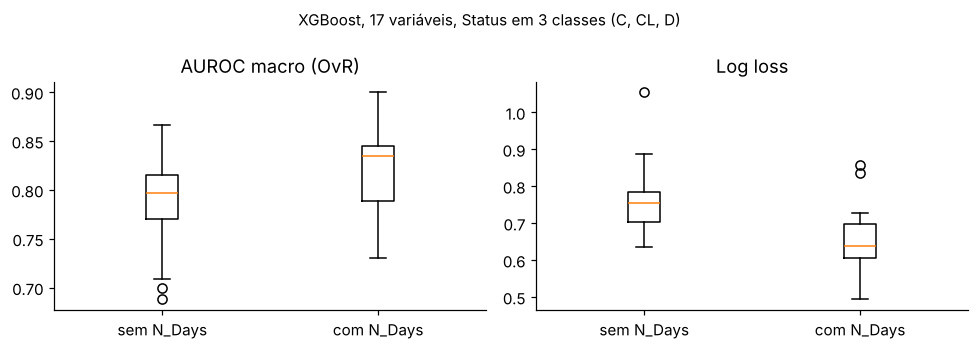

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, met in zip(axs, ["AUROC macro (OvR)", "Log loss"]):
    d = [vz.loc[vz.Entrada == e, met] for e in ["sem N_Days", "com N_Days"]]
    ax.boxplot(d, tick_labels=["sem N_Days", "com N_Days"]); ax.set_title(met)
plt.suptitle("XGBoost, 17 variáveis, Status em 3 classes (C, CL, D)", fontsize=10); plt.tight_layout(); plt.savefig("figs/vazamento_n_days.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Leitura dos resultados

- **Discriminação:** compare cada modelo com a regressão logística com as 5 variáveis de Mayo (referência) pela tabela de valor incremental; só se afirma ganho ou perda quando o IC de Bonferroni exclui zero, e um IC que inclui zero indica ausência de evidência de diferença, não equivalência. O Mayo publicado é só referência histórica.
- **Desenho 2 x 2:** a leitura vertical (mesma coluna) compara pipelines, que diferem no algoritmo e também no tratamento dos dados; a análise de sensibilidade aproxima o efeito do algoritmo ao dar às árvores o pré-processamento da regressão. A leitura horizontal (mesma linha) mostra o efeito nominal das variáveis extras, que não teve contraste inferencial próprio. Exigir as 17 variáveis completas, sem imputação, reduziria os elegíveis de 310 para 210.
- **Calibração:** inclinação próxima de 1 e CITL próximo de 0 indicam probabilidades confiáveis.
- **Vazamento:** a diferença entre os braços com e sem `N_Days` mede o quanto o enquadramento da PS3E26 infla o desempenho.

As conclusões e a discussão estão no `README.md` e no artigo.